In [1]:
import os
os.chdir("/content")
if not os.path.exists("355-mdd-research"):
    !git clone -q https://github.com/jesss77/355-mdd-research.git
os.chdir("/content/355-mdd-research")
!git pull -q

# Step A results live on the external-secondary branch until Jessy merges it
if not os.path.exists("results/external_secondary/metrics.csv"):
    !git fetch -q origin external-secondary
    !git checkout -q FETCH_HEAD -- results/external_secondary

!ls results/external results/external_secondary

results/external:
confusion_matrices.csv	metrics.csv		     predictions.csv
final_gene_set.csv	paired_auroc_comparison.csv  summary.json

results/external_secondary:
auroc_differences.csv  metrics.csv  predictions.csv  settings.json


In [2]:
%%writefile src/make_figures.py
"""Generate the paper figures for the CMPS 355 MDD manuscript.
Run from the repository root:  python src/make_figures.py
Outputs: figures/*.pdf (vector, for LaTeX) and figures/*.png (preview).
"""
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import roc_curve

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "figures"
OUT.mkdir(exist_ok=True)

# ---------------- Style ----------------
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
MODEL_COLOR = {"gene": "#2a78d6", "pathway": "#eb6834", "gene_qn": "#1baf7a", "all_genes": INK_2}
MODEL_MARKER = {"gene": "o", "pathway": "s", "gene_qn": "D", "all_genes": "^"}
MODEL_LABEL = {"gene": "Top-50 genes", "pathway": "50 Hallmark pathways",
               "gene_qn": "Top-50 genes + ref. QN", "all_genes": "All genes (baseline)"}
MODEL_ORDER = ["gene", "pathway", "gene_qn", "all_genes"]
CLASS_COLOR = {0: "#1baf7a", 1: "#6250d6"}
CLASS_MARKER = {0: "o", 1: "^"}
CLASS_LABEL = {0: "Control", 1: "MDD"}
COHORT_LABEL = {"GSE98793": "GSE98793\n(dev., whole blood)",
                "GSE32280": "GSE32280\n(lymphocytes)",
                "GSE39653": "GSE39653\n(PBMC, Illumina)"}
COHORTS = ["GSE98793", "GSE32280", "GSE39653"]
EXTERNAL = ["GSE32280", "GSE39653"]

plt.rcParams.update({
    "font.family": "serif", "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE, "pdf.fonttype": 42,
})
RNG = np.random.default_rng(0)  # jitter only (visual)

def grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, linewidth=0.5, zorder=0); ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUT / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.close(fig); print("saved", name)

def jitter(n, width=0.18):
    return RNG.uniform(-width, width, n)

# ---------------- Load data ----------------
qc = pd.read_csv(ROOT / "metadata" / "expression_qc_samples.csv")
metrics = pd.concat([pd.read_csv(ROOT / "results" / "external" / "metrics.csv"),
                     pd.read_csv(ROOT / "results" / "external_secondary" / "metrics.csv")]
                    ).drop_duplicates(["cohort", "model", "metric"])
pred = pd.read_csv(ROOT / "results" / "external_secondary" / "predictions.csv")
dev = yaml.safe_load(open(ROOT / "config" / "experiment.yaml"))["development_results"]
DEV_AUROC = {"gene": dev["top_50_gene_model"]["nested_cv"]["auroc_mean"],
             "pathway": dev["pathway_model"]["nested_cv"]["auroc_mean"],
             "gene_qn": dev["reference_quantile_sensitivity"]["nested_cv"]["auroc_mean"],
             "all_genes": dev["all_shared_genes_baseline"]["nested_cv"]["auroc_mean"]}

# ---------------- Fig 2: expression distributions ----------------
def fig_expression():
    fig, axes = plt.subplots(1, 2, figsize=(3.5, 1.9), constrained_layout=True)
    for ax, col, title in [(axes[0], "median", "Per-sample median"), (axes[1], "iqr", "Per-sample IQR")]:
        for i, c in enumerate(COHORTS):
            v = qc.loc[qc.cohort == c, col].to_numpy()
            ax.scatter(i + jitter(len(v)), v, s=6, color=INK_2, alpha=0.55, linewidths=0, zorder=3)
            ax.hlines(np.median(v), i - 0.3, i + 0.3, color=INK, linewidth=1.4, zorder=4)
        ax.set_xticks(range(3)); ax.set_xticklabels(COHORTS, rotation=25, ha="right")
        ax.set_title(title, color=INK)
        ax.set_ylabel("log$_2$ expression" if col == "median" else "log$_2$ expression range")
        grid(ax)
    axes[1].set_ylim(0, None)
    save(fig, "fig2_expression_distributions")

# ---------------- Fig 3: external AUROC forest plot ----------------
def fig_forest():
    fig, axes = plt.subplots(2, 1, figsize=(3.5, 2.9), sharex=True, constrained_layout=True)
    auc = metrics[metrics.metric == "auroc"]
    for ax, c in zip(axes, EXTERNAL):
        n = int(pred[(pred.cohort == c) & (pred.model == "gene")].shape[0])
        for j, m in enumerate(MODEL_ORDER):
            r = auc[(auc.cohort == c) & (auc.model == m)].iloc[0]
            y = len(MODEL_ORDER) - 1 - j
            ax.hlines(y, r.ci_low, r.ci_high, color=MODEL_COLOR[m], linewidth=1.6, zorder=3)
            ax.scatter(r.estimate, y, marker=MODEL_MARKER[m], s=26, color=MODEL_COLOR[m],
                       edgecolors=SURFACE, linewidths=0.8, zorder=4)
            ax.text(1.02, y, f"{r.estimate:.2f} ({r.ci_low:.2f}–{r.ci_high:.2f})", va="center",
                    ha="left", fontsize=6.3, color=INK_2, transform=ax.get_yaxis_transform())
        ax.axvline(0.5, color=INK_2, linestyle=(0, (3, 2)), linewidth=0.7, zorder=2)
        ax.set_yticks(range(len(MODEL_ORDER)))
        ax.set_yticklabels([MODEL_LABEL[m] for m in MODEL_ORDER[::-1]])
        ax.set_ylim(-0.6, len(MODEL_ORDER) - 0.4)
        ax.set_title(f"{c}  (n = {n})", loc="left", color=INK)
        grid(ax, "x")
    axes[-1].set_xlim(0, 1); axes[-1].set_xlabel("External AUROC (95% bootstrap CI)")
    save(fig, "fig3_external_auroc_forest")

# ---------------- Fig 4: ROC curves ----------------
def fig_roc():
    fig, axes = plt.subplots(1, 2, figsize=(3.5, 2.15), sharey=True, constrained_layout=True)
    auc = metrics[metrics.metric == "auroc"]
    for ax, c in zip(axes, EXTERNAL):
        ax.plot([0, 1], [0, 1], color=INK_2, linestyle=(0, (3, 2)), linewidth=0.7)
        a = {}
        for m in ["gene", "pathway"]:
            d = pred[(pred.cohort == c) & (pred.model == m)]
            fpr, tpr, _ = roc_curve(d.label, d.prob_mdd)
            a[m] = auc[(auc.cohort == c) & (auc.model == m)].estimate.iloc[0]
            ax.step(fpr, tpr, where="post", color=MODEL_COLOR[m], linewidth=1.6,
                    label="Top-50 genes" if m == "gene" else "Pathways")
        ax.set_title(f"{c}\ngenes {a['gene']:.2f} | pathways {a['pathway']:.2f}", color=INK, fontsize=7)
        ax.set_xlabel("False positive rate")
        ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
        grid(ax, "both")
    axes[0].set_ylabel("True positive rate")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside upper center", ncol=2, frameon=False)
    save(fig, "fig4_roc_curves")

# ---------------- Fig 5: predicted probabilities (exploratory) ----------------
def fig_probabilities():
    models = ["gene", "pathway", "gene_qn"]
    short = {"gene": "Top-50 genes", "pathway": "Pathways", "gene_qn": "Genes + QN"}
    fig, axes = plt.subplots(3, 2, figsize=(3.5, 3.0), sharex=True, constrained_layout=True)
    for i, m in enumerate(models):
        for k, c in enumerate(EXTERNAL):
            ax = axes[i, k]
            d = pred[(pred.cohort == c) & (pred.model == m)]
            for lab in (0, 1):
                v = d.loc[d.label == lab, "prob_mdd"].to_numpy()
                ax.scatter(v, lab + jitter(len(v), 0.15), s=10, marker=CLASS_MARKER[lab],
                           color=CLASS_COLOR[lab], edgecolors=SURFACE, linewidths=0.4,
                           zorder=3, label=CLASS_LABEL[lab])
            ax.axvline(0.5, color=INK_2, linestyle=(0, (3, 2)), linewidth=0.7)
            ax.set_yticks([0, 1]); ax.set_yticklabels(["Ctrl", "MDD"])
            ax.set_ylim(-0.5, 1.5); ax.set_xlim(0, 1)
            grid(ax, "x")
            if i == 0: ax.set_title(c, color=INK)
            if k == 0: ax.set_ylabel(short[m], fontsize=6.5)
    for ax in axes[-1]: ax.set_xlabel("Predicted P(MDD)")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside upper center", ncol=2, frameon=False)
    save(fig, "fig5_predicted_probabilities")

# ---------------- Fig S1: development vs external ----------------
def fig_dev_vs_external():
    auc = metrics[metrics.metric == "auroc"]
    fig, ax = plt.subplots(figsize=(3.5, 2.1), constrained_layout=True)
    ax.axhline(0.5, color=INK_2, linestyle=(0, (3, 2)), linewidth=0.7)
    for m in MODEL_ORDER:
        ys = [DEV_AUROC[m]] + [auc[(auc.cohort == c) & (auc.model == m)].estimate.iloc[0] for c in EXTERNAL]
        ax.plot([0, 1, 2], ys, color=MODEL_COLOR[m], linewidth=1.4, marker=MODEL_MARKER[m],
                markersize=4.5, markeredgecolor=SURFACE, markeredgewidth=0.6, label=MODEL_LABEL[m], zorder=3)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["GSE98793\n(nested CV)", "GSE32280\n(external)", "GSE39653\n(external)"])
    ax.set_ylabel("AUROC"); ax.set_ylim(0.3, 0.8)
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
    grid(ax)
    save(fig, "figS1_dev_vs_external")

# ---------------- Fig S2: heme metabolism ----------------
def fig_heme():
    fig, ax = plt.subplots(figsize=(3.5, 1.8), constrained_layout=True)
    for i, c in enumerate(COHORTS):
        f = pd.read_csv(ROOT / "data" / "features" / f"{c}_hallmark_ssgsea.csv", index_col="GSM")
        v = f["HALLMARK_HEME_METABOLISM"].to_numpy()
        ax.scatter(i + jitter(len(v)), v, s=6, color=INK_2, alpha=0.55, linewidths=0, zorder=3)
        ax.hlines(np.median(v), i - 0.3, i + 0.3, color=INK, linewidth=1.4, zorder=4)
    ax.set_xticks(range(3)); ax.set_xticklabels([COHORT_LABEL[c] for c in COHORTS])
    ax.set_ylabel("Heme metabolism ssGSEA ES")
    grid(ax)
    save(fig, "figS2_heme_metabolism")

if __name__ == "__main__":
    fig_expression(); fig_forest(); fig_roc()
    fig_probabilities(); fig_dev_vs_external(); fig_heme()

Writing src/make_figures.py


saved fig2_expression_distributions
saved fig3_external_auroc_forest
saved fig4_roc_curves
saved fig5_predicted_probabilities
saved figS1_dev_vs_external
saved figS2_heme_metabolism
fig2_expression_distributions


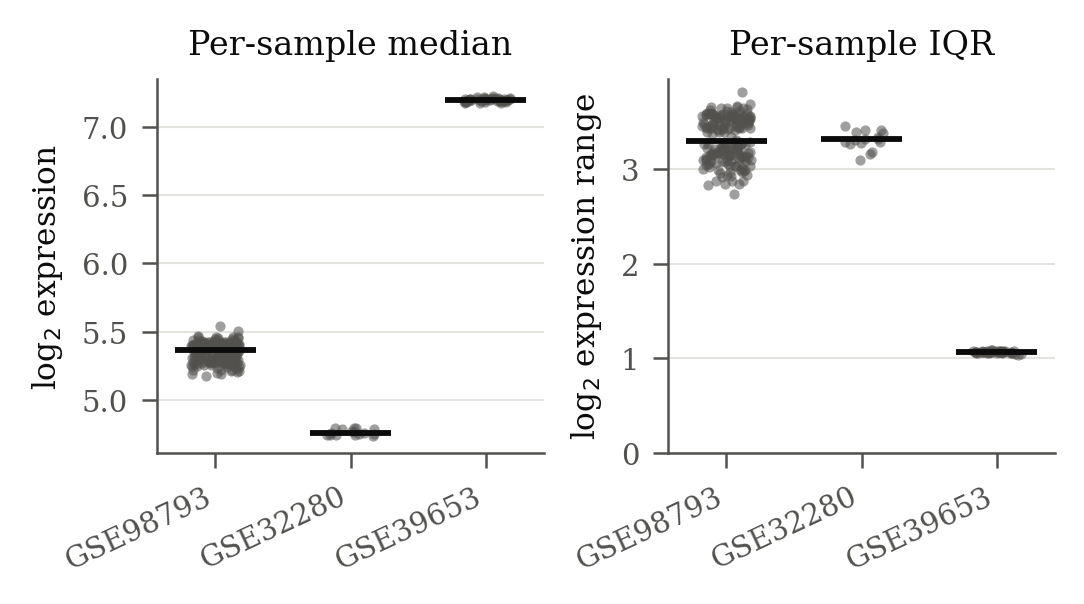

fig3_external_auroc_forest


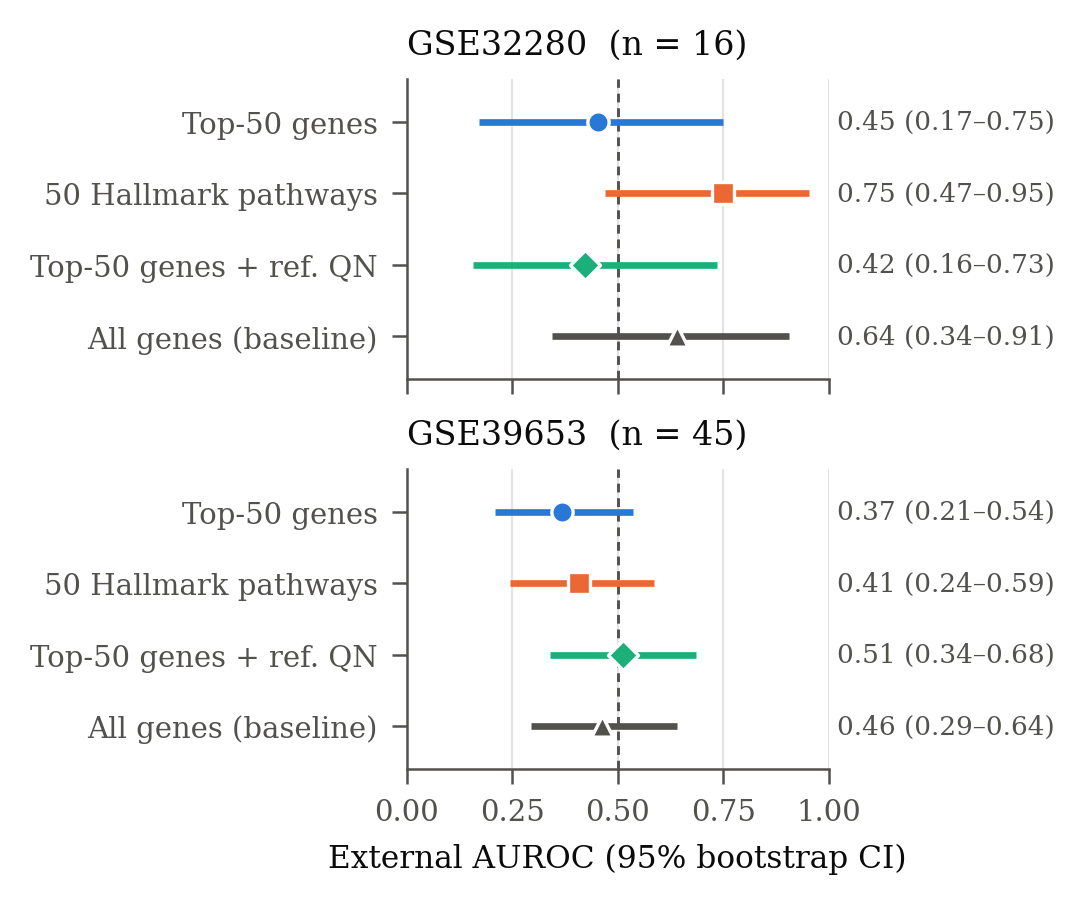

fig4_roc_curves


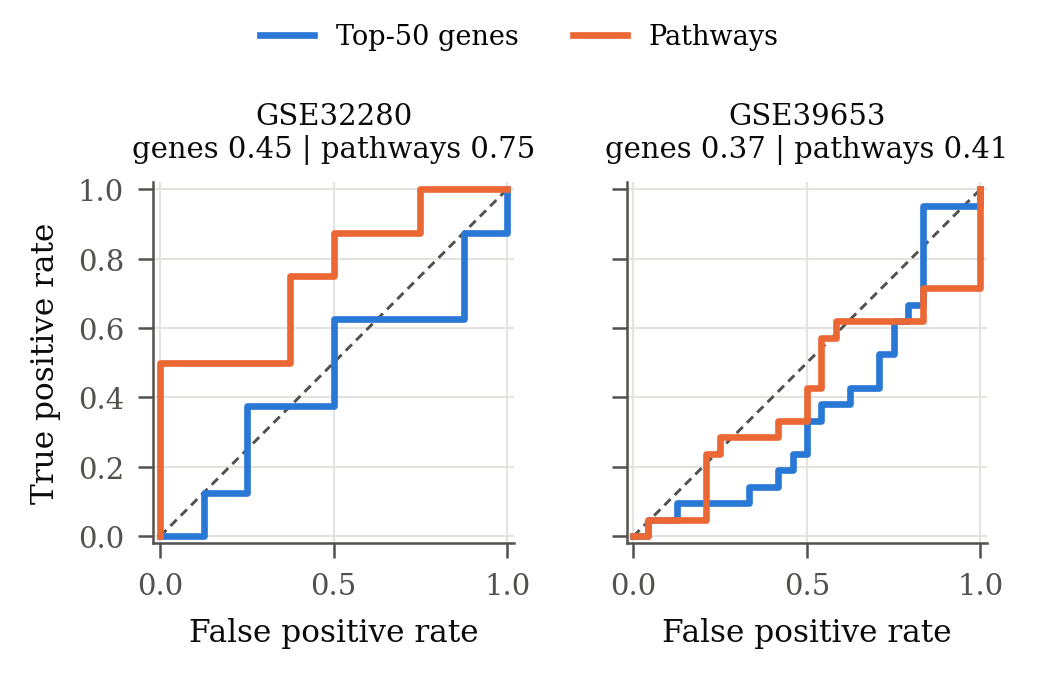

fig5_predicted_probabilities


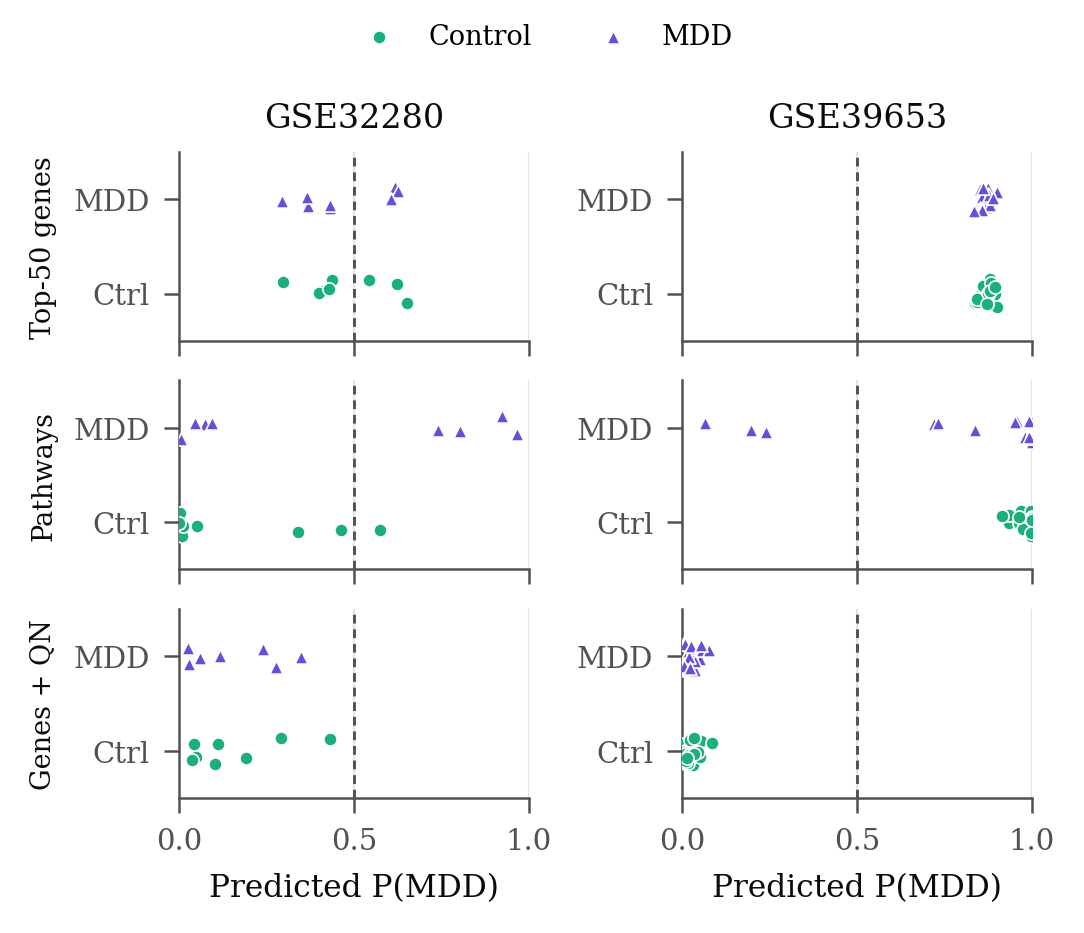

figS1_dev_vs_external


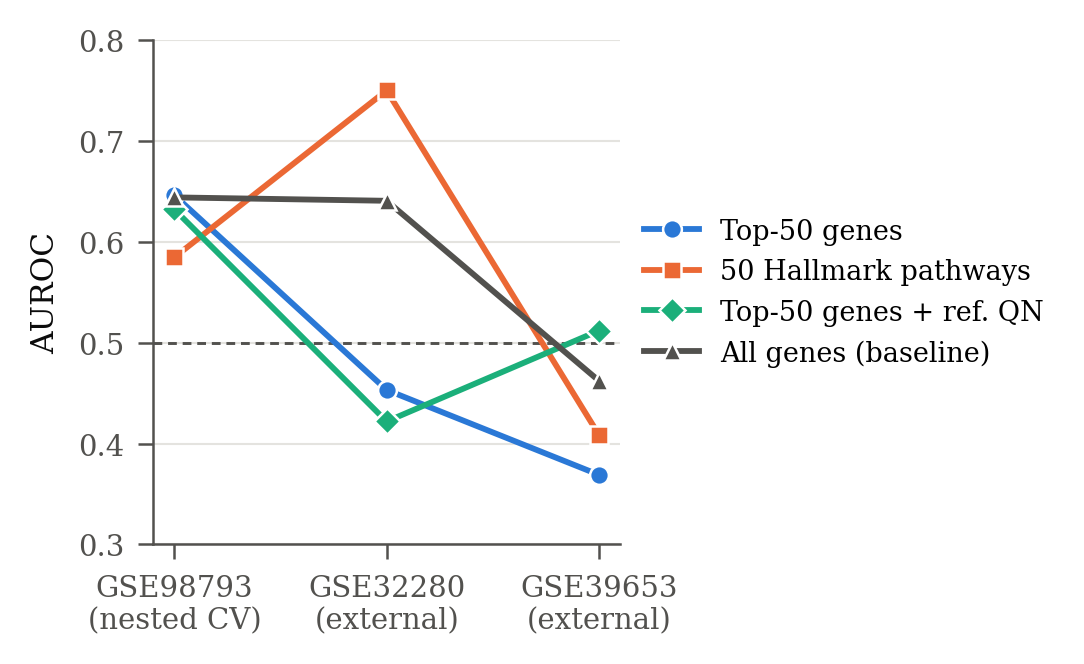

figS2_heme_metabolism


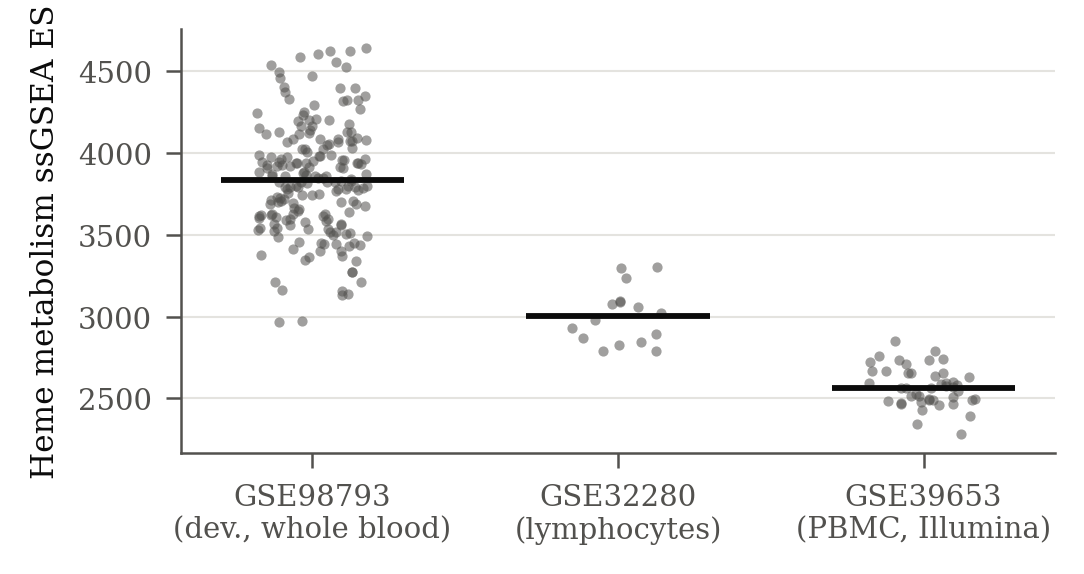

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
!python src/make_figures.py

from IPython.display import Image, display
for name in ["fig2_expression_distributions", "fig3_external_auroc_forest", "fig4_roc_curves",
             "fig5_predicted_probabilities", "figS1_dev_vs_external", "figS2_heme_metabolism"]:
    print(name); display(Image(f"figures/{name}.png", width=450))

!mkdir -p /content/images && cp figures/*.pdf /content/images/
!cd /content && zip -qr paper_figures.zip images
from google.colab import files
files.download("/content/paper_figures.zip")

In [4]:
!cd /content/355-mdd-research && zip -qr /content/figures_for_github.zip figures src/make_figures.py
from google.colab import files
files.download("/content/figures_for_github.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>